<a href="https://colab.research.google.com/github/vibhar5/4IK25CS237_DAV_LAB/blob/main/4IK25CS237_EXP_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix,ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score,classification_report)

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')

In [ ]:
df = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

In [ ]:
x=df[['Pclass','Sex','Age','SibSp','Parch','Embarked']]
y=df['Survived']

In [ ]:
X_tr,X_te,y_tr,y_te=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
clf=LogisticRegression(max_iter=1000)
clf.fit(X_tr,y_tr)
y_pred=clf.predict(X_te)

In [ ]:
print('Accuracy :', round(accuracy_score(y_te,y_pred),3))
print('Precision :', round(precision_score(y_te,y_pred),3))
print('Recall :', round(recall_score(y_te,y_pred),3))
print('F1 Score :', round(f1_score(y_te,y_pred),3))
print(classification_report(y_te,y_pred))

Accuracy : 0.816
Precision : 0.79
Recall : 0.71
F1 Score : 0.748
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       110
           1       0.79      0.71      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



Confusion Matrix:
 [[97 13]
 [20 49]]


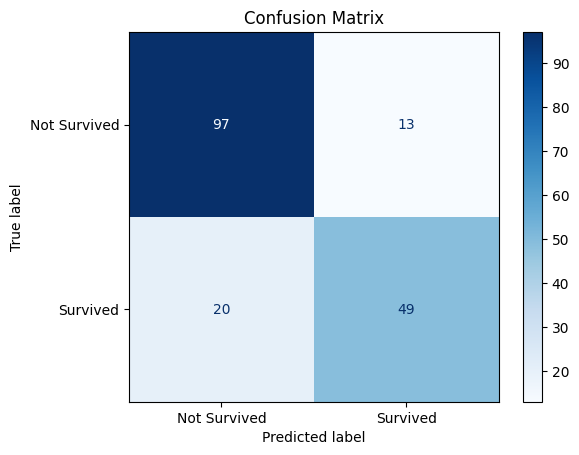

In [ ]:
cm = confusion_matrix(y_te, y_pred, labels=[0,1])
print('Confusion Matrix:\n', cm)
ConfusionMatrixDisplay(cm, display_labels = ['Not Survived', 'Survived']).plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()